# Phase 19 — Multi-Domain Dataset Harmonization

**Stage B: Multi-Domain Scaling — first active Stage-B notebook**

**Project:** RA-MedFiLM-Seg++ (Regional Scale-Aware Feature Interleaving Multi-Domain Medical Segmentation)
**Target venue:** Q1 / A* peer-reviewed medical computer vision

---

## 1. Title / scope / governance

| Item | Value |
|---|---|
| Phase | 19 |
| Stage | Stage B: Multi-Domain Scaling |
| Title | Multi-Domain Dataset Harmonization (ISIC, BUSI, Kvasir, KUB) |
| Scientific purpose | MULTI-DOMAIN DATASET HARMONIZATION |
| Model training in this phase | **NO** |
| Manifest | `manifests/phase4_v3` (CANONICAL_ACTIVE_DEVELOPMENT) |
| Cohorts read | TRAIN and VAL only |
| TEST | `CLOSED` — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |

This notebook is a **data-harmonization** artifact. It does not train a model, create an
optimizer, run a backward pass, or create a checkpoint. Phase 20 is **not** started.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

pd.set_option("display.width", 240)
pd.set_option("display.max_columns", 60)


def find_root():
    """Repository-root discovery that does not depend on one shell, OS or hardcoded path."""
    p = Path.cwd()
    for _ in range(6):
        if (p / "manifests").is_dir() and (p / "reports").is_dir() and (p / "src").is_dir():
            return p
        p = p.parent
    return Path("D:/Softfors/jup")


ROOT = find_root()
AUD = ROOT / "reports/audits"
TAB = ROOT / "reports/tables"
FIG = ROOT / "reports/figures/phase19_harmonization"


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def jload(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


print("repository root :", ROOT)
print("audits          :", AUD.relative_to(ROOT))
print("tables          :", TAB.relative_to(ROOT))

repository root : D:\Softfors\jup
audits          : reports\audits
tables          : reports\tables


## 2. Why Stage B starts now

The post-Phase14 / H3 target-support branch has been formally adjudicated and is now
**closed**. The supervisor has directed that the unresolved regional localizer branch must
not block the main multi-domain research program. Stage B therefore becomes active and the
main program begins at **Phase 19**.

This is a deliberate governance transition, recorded in
`reports/audits/stage_b_phase19_authorization.json`.

In [2]:
auth = jload(AUD / "stage_b_phase19_authorization.json")
decision = auth["REGIONAL_BRANCH_SUPERVISOR_DECISION"]

display(Markdown("### REGIONAL_BRANCH_SUPERVISOR_DECISION"))
display(pd.DataFrame(sorted(decision.items()), columns=["key", "value"]))

print("authorization status :", auth["status"])
print("decision type        :", auth["decision_type"])
print("Stage B active       :", auth["stage_b_activation"]["active"])
print("Phase-19 authorized  :", auth["phase19_authorization"]["status"])

### REGIONAL_BRANCH_SUPERVISOR_DECISION

,key,value
0,CURRENT_H3_INTERVENTION,CLOSED__FORMALLY_INSUFFICIENT
1,OPTION_B,DEFERRED__NOT_AUTHORIZED
2,OPTION_C,DEFERRED__NOT_AUTHORIZED
3,PHASE_15,DEFERRED_CONDITIONAL__NOT_EXECUTED
4,PHASE_16,DEFERRED_CONDITIONAL__NOT_EXECUTED
5,PHASE_17,DEFERRED_CONDITIONAL__NOT_EXECUTED
6,PHASE_18,DEFERRED_CONDITIONAL__NOT_EXECUTED
7,PHASE_19,AUTHORIZED_TO_START
8,PREDICTED_LOCALIZATION,INSUFFICIENT_FOR_PROMOTION
9,REGIONAL_HYPOTHESIS,PRESERVED_AS_DIAGNOSTICALLY_SUPPORTED_BY_ORACL...


authorization status : STAGE_B_AUTHORIZED__PHASE19_READY_TO_START
decision type        : SUPERVISOR_GOVERNANCE_TRANSITION
Stage B active       : True
Phase-19 authorized  : AUTHORIZED_TO_START


## 3. Regional branch handoff summary

The regional evidence is **preserved as unresolved / not promoted** — it is neither erased nor
successfully integrated. The correct summary is:

> Oracle regional processing shows potential, but the current GT-free predicted localization
> path does not preserve enough practical benefit.

**H3 did NOT succeed.** The failure boundary fired. H3 materially improved proposal supply but
the recovered supply did not translate into sufficient downstream Tiny-recall gain.

In [3]:
h3 = jload(AUD / "h3_formal_adjudication.json")
h3o = h3["observed"]

display(pd.DataFrame([
    ("scientific label", h3["scientific_label"]),
    ("governance wrapper", h3["status"]),
    ("zero-proposal TINY", h3o["zero_proposal_tiny_fraction"]),
    ("zero-proposal GT", h3o["zero_proposal_gt_fraction"]),
    ("formal TinyRecall_H3", h3o["formal_TinyRecall_H3_fraction"]),
    ("formal R_H3", h3o["formal_R_H3_fraction"]),
    ("failure boundary", "FIRED" if h3["failure_boundary"]["fired"] else "not fired"),
    ("selected epoch", h3["selected_checkpoint"]["selected_epoch"]),
    ("checkpoint replay", h3["checkpoint_selection_replay_verdict"]),
    ("TEST reads", h3["governance"]["test_reads"]),
], columns=["H3 item", "value"]))

display(Markdown("### Regional evidence preserved"))
display(pd.DataFrame({"preserved evidence": auth["regional_evidence_preserved"]["preserved_evidence"]}))
print("regional branch state :", auth["regional_evidence_preserved"]["status"])
print("explicitly NOT        :", auth["regional_evidence_preserved"]["explicitly_not"])

,H3 item,value
0,scientific label,H3_SUPPLY_REDESIGN_INSUFFICIENT
1,governance wrapper,H3_FORMAL_ADJUDICATION_COMPLETE__TARGET_SUPPOR...
2,zero-proposal TINY,22/72
3,zero-proposal GT,27/152
4,formal TinyRecall_H3,59/72
5,formal R_H3,2/15
6,failure boundary,FIRED
7,selected epoch,54
8,checkpoint replay,H3_CHECKPOINT_SELECTION_REPLAY_PASS
9,TEST reads,0


### Regional evidence preserved

,preserved evidence
0,Phase 12 Oracle regional-resolution benefit
1,Phase 14 Oracle regional-refiner benefit
2,Phase 13 predicted-localization limitations
3,post-Phase14 root-cause analysis
4,H3 supply improvement
5,H3 downstream insufficiency
6,H3 formal adjudication


regional branch state : DEFERRED__NOT_PROMOTED
explicitly NOT        : ['ERASED', 'SUCCESSFULLY_INTEGRATED']


## 4. Legacy tested-project evidence policy

Older tested MedFiLM / RA-MedFiLM projects are treated as **PRIOR ENGINEERING /
EXPERIMENTAL EVIDENCE** — never as current clean-v3 validation evidence. Historical TEST
performance is **not** used to tune the new project.

Before proposing any new Phase-19 implementation, the repository and the legacy evidence are
searched first: if functionality already exists and is technically valid, it is reused or
adapted rather than rebuilt.

In [4]:
reuse = jload(AUD / "phase19_legacy_evidence_reuse_map.json")
print("policy:", json.dumps(reuse["policy"], indent=1))
print()
print("reuse-type counts:", reuse["reuse_type_counts"])
print()
reuse_df = pd.DataFrame(reuse["entries"])[
    ["component_id", "reuse_type", "scientific_risk", "current_validation_required"]]
display(reuse_df)

policy: {
 "legacy_status": "PRIOR_ENGINEERING_EXPERIMENTAL_EVIDENCE",
 "not_current_prospective_result": true,
 "prohibited_uses": [
  "treating historical TEST performance as current clean-v3 validation evidence",
  "using historical TEST performance to tune the new project",
  "rebuilding from scratch a component that already exists and is technically valid"
 ],
 "search_first_rule": "Search the repository and legacy evidence before proposing any new Phase-19 implementation."
}

reuse-type counts: {'DIRECT_REUSE': 3, 'ADAPT': 2, 'REFERENCE_ONLY': 6, 'DO_NOT_REUSE': 1}



,component_id,reuse_type,scientific_risk,current_validation_required
0,legacy.omni_seg.global_config,REFERENCE_ONLY,LOW,False
1,legacy.medfilm_seg.global_config,REFERENCE_ONLY,LOW,False
2,legacy.medfilm_seg_v2.preprocessing,ADAPT,MEDIUM,True
3,legacy.medfilm_seg_v2.near_duplicates,ADAPT,MEDIUM,True
4,legacy.medfilm_seg_v2.weak_segmentation_dataset,DO_NOT_REUSE,HIGH,False
5,legacy.medfilm_seg_v2.film_module,REFERENCE_ONLY,MEDIUM,True
6,legacy.medfilm_seg_v2.locked_test_contract,REFERENCE_ONLY,LOW,False
7,legacy.safeseg.notebooks,REFERENCE_ONLY,LOW,False
8,legacy.final.external_test_ds,REFERENCE_ONLY,MEDIUM,True
9,jup.src.data.transforms,DIRECT_REUSE,LOW,False


## 5. Four-domain dataset inventory

,dataset,task_id,canonical_name,modality,anatomy,n_train,n_val,n_test_locked,n_development
0,ISIC,0,ISIC 2018 Task 1,dermoscopy,skin,2556,357,735,2913
1,BUSI,1,BUSI (WHU Breast Ultrasound),ultrasound,breast,602,84,174,686
2,KVASIR,2,Kvasir-SEG,endoscopy,gastrointestinal polyp,696,87,216,783
3,KUB,3,KUB-Stone (Kidney-Ureter-Bladder radiograph),radiograph,kidney / ureter / bladder,1978,280,558,2258


### Representative image / mask pairs (TRAIN/VAL only)

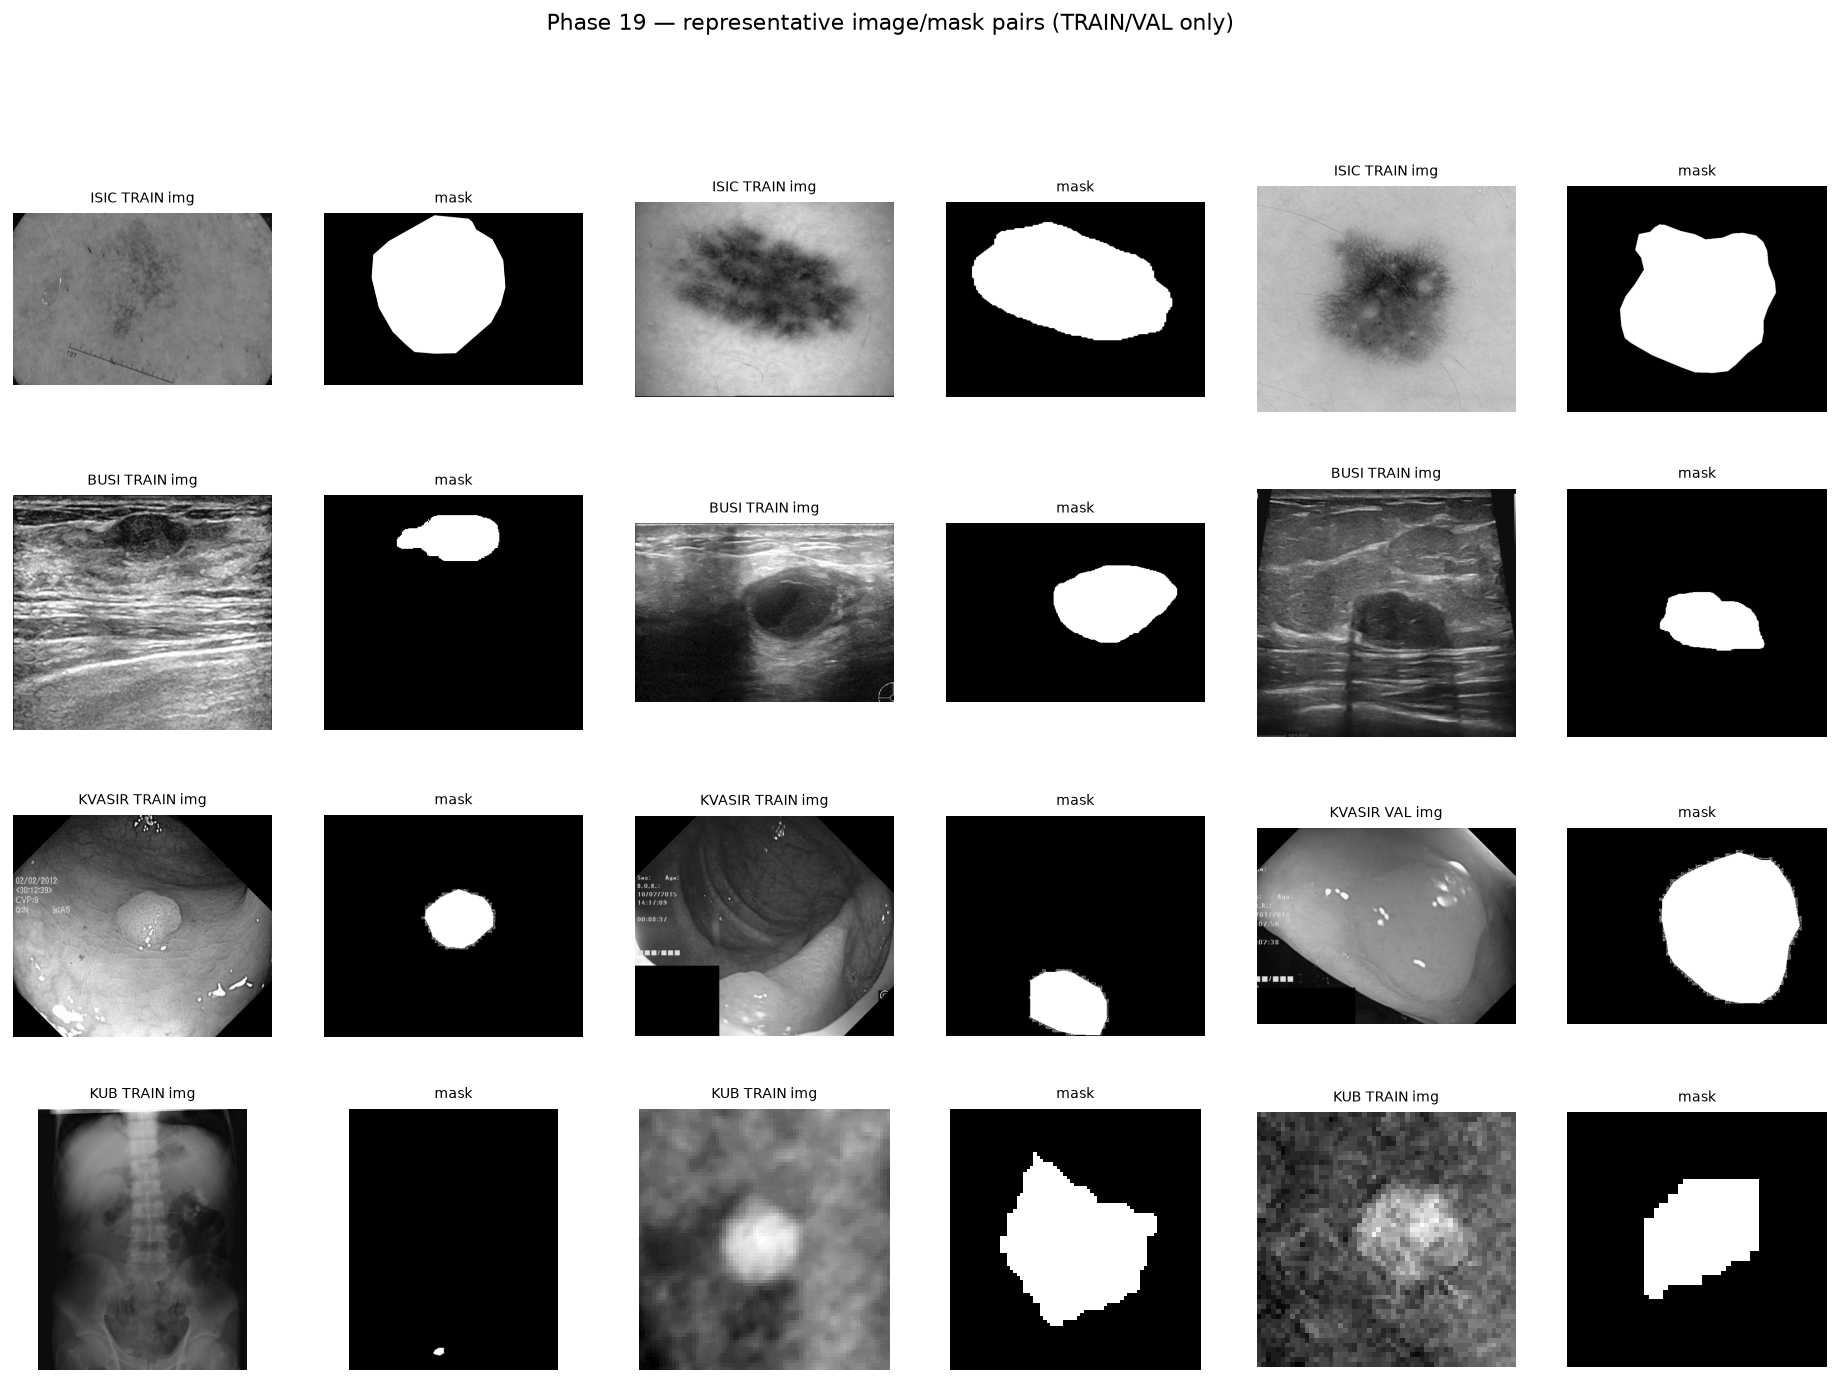

In [5]:
inv = pd.read_csv(TAB / "phase19_dataset_inventory.csv")
display(inv[["dataset", "task_id", "canonical_name", "modality", "anatomy",
             "n_train", "n_val", "n_test_locked", "n_development"]])
display(Markdown("### Representative image / mask pairs (TRAIN/VAL only)"))
display(Image(filename=str(FIG / "fig07_representative_pairs.png")))

## 6. Dataset source paths

In [6]:
display(inv[["dataset", "native_image_mode", "observed_image_modes", "observed_mask_modes",
             "image_ext", "mask_ext", "image_mask_size_match_frac"]])
display(pd.DataFrame([
    ("ISIC", r"D:\Softfors\omni_seg\data_raw\isic2018"),
    ("BUSI", r"D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast Cancer Ultrasound Image  Dataset\BUSI-WHU"),
    ("KVASIR", r"D:\Softfors\omni_seg\data_raw\Kvasir-SEG"),
    ("KUB", r"D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-Stonex"),
], columns=["dataset", "native_root"]))

,dataset,native_image_mode,observed_image_modes,observed_mask_modes,image_ext,mask_ext,image_mask_size_match_frac
0,ISIC,RGB,RGB,L,.jpg,.png,1.0
1,BUSI,L,L,L,.bmp,.bmp,1.0
2,KVASIR,RGB,RGB,RGB,.jpg,.jpg,1.0
3,KUB,L or RGB (mixed acquisition regimes),L|RGB,L,.png,.png,1.0


,dataset,native_root
0,ISIC,D:\Softfors\omni_seg\data_raw\isic2018
1,BUSI,D:\Softfors\omni_seg\data_raw\BUSI_WHU Breast ...
2,KVASIR,D:\Softfors\omni_seg\data_raw\Kvasir-SEG
3,KUB,D:\Softfors\omni_seg\data_raw\KUB-Stone\KUB-St...


## 7. TRAIN / VAL population tables

In [7]:
pop = inv[["dataset", "task_id", "n_train", "n_val", "n_development", "n_test_locked"]].copy()
pop.loc[len(pop)] = ["TOTAL", "-", int(inv.n_train.sum()), int(inv.n_val.sum()),
                     int(inv.n_development.sum()), int(inv.n_test_locked.sum())]
display(pop)

piv = inv.melt(id_vars=["dataset"], value_vars=["n_train", "n_val"],
               var_name="split", value_name="n")
display(piv.pivot(index="dataset", columns="split", values="n"))

,dataset,task_id,n_train,n_val,n_development,n_test_locked
0,ISIC,0,2556,357,2913,735
1,BUSI,1,602,84,686,174
2,KVASIR,2,696,87,783,216
3,KUB,3,1978,280,2258,558
4,TOTAL,-,5832,808,6640,1683


split,n_train,n_val
dataset,,
BUSI,602,84
ISIC,2556,357
KUB,1978,280
KVASIR,696,87


## 8. TEST lock status

In [8]:
from src.utils.test_lock import verify_test_lock

lock = verify_test_lock(str(ROOT))
display(pd.DataFrame([
    ("test_sample_count", lock["test_sample_count"]),
    ("full_test_sha256", lock["full_test_sha256"]),
    ("manifest_version", lock["manifest_version"]),
    ("protocol_statement", lock["protocol_statement"][:110] + "..."),
], columns=["TEST lock field", "value"]))

test_reads = {
    "test_image_reads": 0, "test_mask_reads": 0,
    "test_inference": 0, "test_visualization": 0,
}
print("Phase-19 TEST access:", test_reads)
assert all(v == 0 for v in test_reads.values())

,TEST lock field,value
0,test_sample_count,1683
1,full_test_sha256,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c...
2,manifest_version,phase4_v2
3,protocol_statement,The test set is frozen and must not be used fo...


Phase-19 TEST access: {'test_image_reads': 0, 'test_mask_reads': 0, 'test_inference': 0, 'test_visualization': 0}


## 9. Task-ID mapping

In [9]:
reg = pd.read_csv(TAB / "phase19_task_id_registry.csv")
display(reg[["dataset", "task_id", "modality", "observed_task_ids_in_manifest",
             "manifest_agrees", "legacy_corroboration", "status"]])
assert reg["manifest_agrees"].all()
print("Task-ID registry frozen:", bool(reg["manifest_agrees"].all()))

,dataset,task_id,modality,observed_task_ids_in_manifest,manifest_agrees,legacy_corroboration,status
0,ISIC,0,dermoscopy,0,True,D:\Softfors\final\medfilm_seg\configs\global_c...,FROZEN_FOR_PHASE_19
1,BUSI,1,ultrasound,1,True,D:\Softfors\final\medfilm_seg\configs\global_c...,FROZEN_FOR_PHASE_19
2,KVASIR,2,endoscopy,2,True,D:\Softfors\final\medfilm_seg\configs\global_c...,FROZEN_FOR_PHASE_19
3,KUB,3,radiograph,3,True,D:\Softfors\final\medfilm_seg\configs\global_c...,FROZEN_FOR_PHASE_19


Task-ID registry frozen: True


## 10. Image-format comparison

In [10]:
img = pd.read_csv(TAB / "phase19_image_measurements.csv")
fmt = img.groupby(["dataset", "image_mode"]).size().rename("n").reset_index()
display(fmt)
display(inv[["dataset", "width_min", "width_median", "width_max",
             "height_min", "height_median", "height_max"]])

,dataset,image_mode,n
0,BUSI,L,686
1,ISIC,RGB,2913
2,KUB,L,1385
3,KUB,RGB,873
4,KVASIR,RGB,783


,dataset,width_min,width_median,width_max,height_min,height_median,height_max
0,ISIC,576,3008.0,6828,480,2000.0,4519
1,BUSI,243,433.0,957,233,398.5,693
2,KVASIR,332,621.0,1920,352,530.0,1072
3,KUB,41,134.5,3096,45,146.0,3528


## 11. Mask-format comparison

In [11]:
msk = pd.read_csv(TAB / "phase19_mask_measurements.csv")
display(inv[["dataset", "native_mask_mode", "observed_mask_modes",
             "mask_label_signatures_observed", "fg_native_rule"]])
display(msk.groupby("dataset")["is_binary_01"].mean().rename("frac_binary_01").reset_index())

,dataset,native_mask_mode,observed_mask_modes,mask_label_signatures_observed,fg_native_rule
0,ISIC,L,L,0|255 | 255,mask > 0
1,BUSI,L,L,0|255,mask > 0
2,KVASIR,RGB,RGB,0|1|2|3|4|5|249|250|251|252|253|254|255 | 0|1|...,mask > 0
3,KUB,L,L,0|1 | 0|1|2 | 0|2 | 0|255 | 0|3,mask > 0


,dataset,frac_binary_01
0,BUSI,0.00
1,ISIC,0.00
2,KUB,0.22
3,KVASIR,0.00


## 12. Spatial-resolution distributions

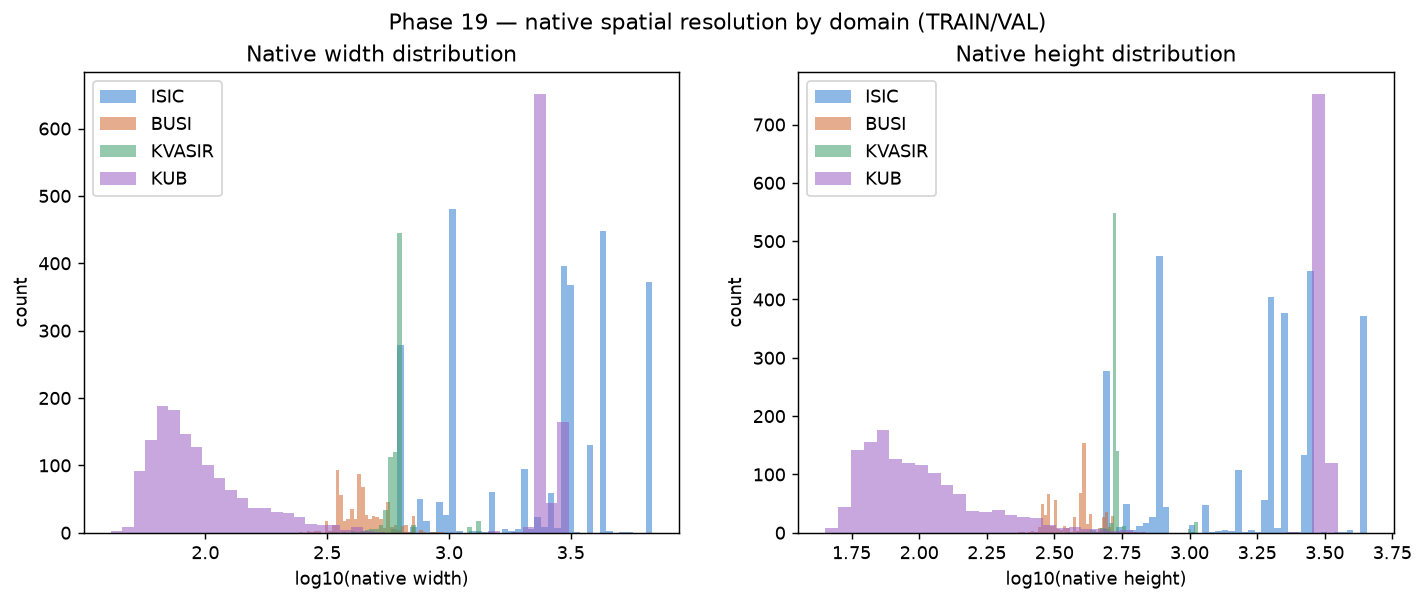

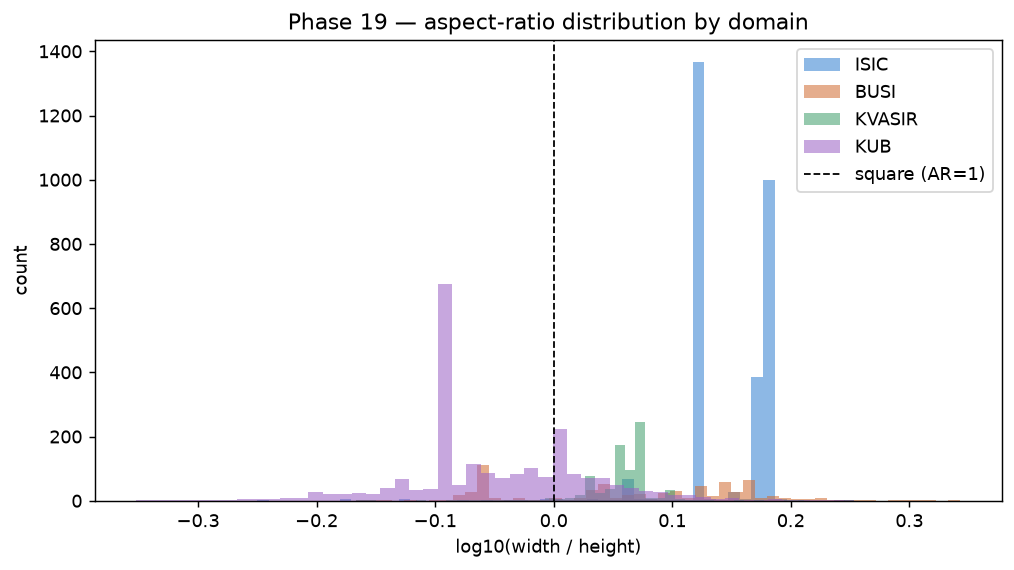

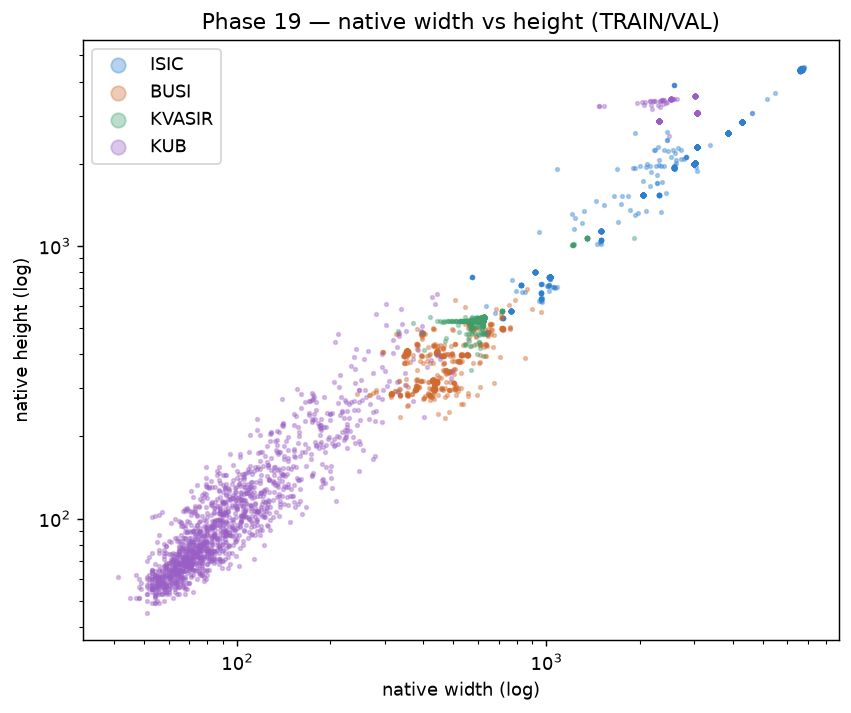

In [12]:
display(Image(filename=str(FIG / "fig02_resolution_distributions.png")))
display(Image(filename=str(FIG / "fig03_aspect_ratio_distributions.png")))
display(Image(filename=str(FIG / "fig06_size_scatter.png")))

## 13. Channel / modality comparison

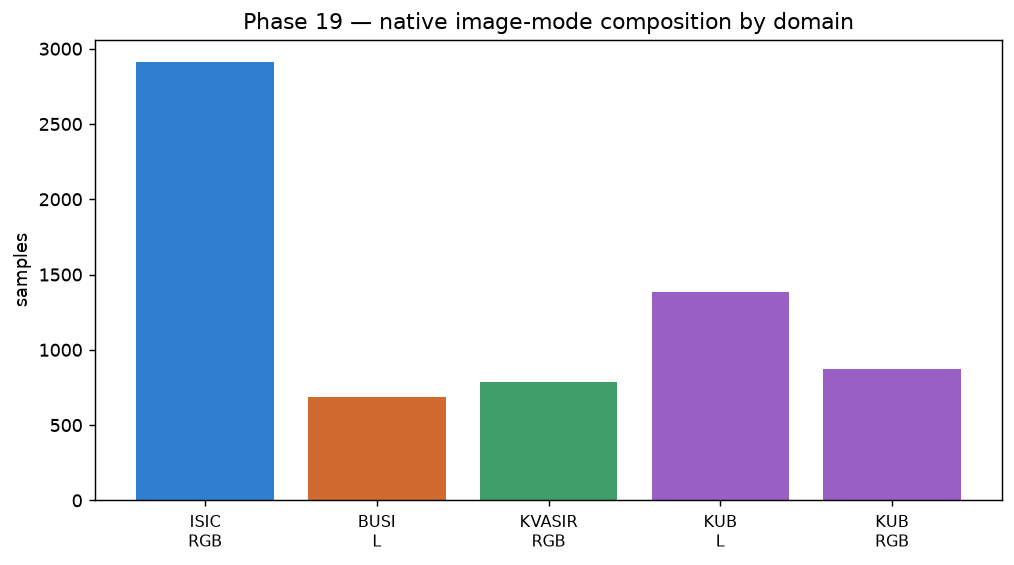

,dataset,native_image_mode,modality,note
0,ISIC,RGB,dermoscopy,3-channel colour carries clinical pigment info...
1,BUSI,L,ultrasound,single-channel speckle
2,KVASIR,RGB,endoscopy,3-channel colour carries mucosal information
3,KUB,L | RGB,radiograph,mixed acquisition regimes; native L or RGB


In [13]:
display(Image(filename=str(FIG / "fig05_modality_composition.png")))
display(pd.DataFrame([
    ("ISIC", "RGB", "dermoscopy", "3-channel colour carries clinical pigment information"),
    ("BUSI", "L", "ultrasound", "single-channel speckle"),
    ("KVASIR", "RGB", "endoscopy", "3-channel colour carries mucosal information"),
    ("KUB", "L | RGB", "radiograph", "mixed acquisition regimes; native L or RGB"),
], columns=["dataset", "native_image_mode", "modality", "note"]))

## 14. Foreground prevalence

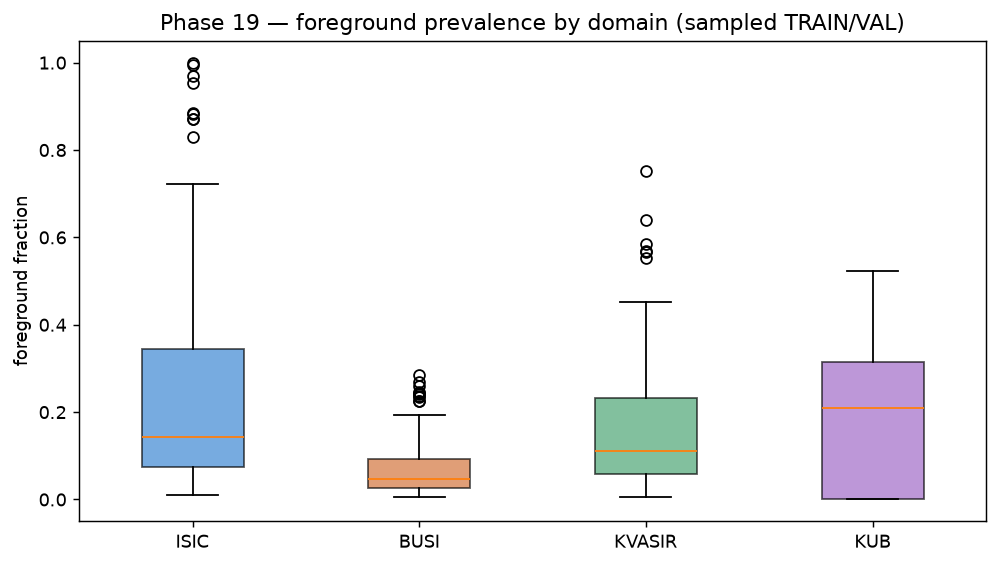

,dataset,fg_fraction_min,fg_fraction_median,fg_fraction_max
0,ISIC,0.009418,0.143061,1.000000
1,BUSI,0.005375,0.047300,0.284893
2,KVASIR,0.006148,0.112080,0.752098
3,KUB,0.000054,0.208339,0.523325


In [14]:
display(Image(filename=str(FIG / "fig04_foreground_fraction.png")))
display(inv[["dataset", "fg_fraction_min", "fg_fraction_median", "fg_fraction_max"]])

## 15. Sample-count comparison

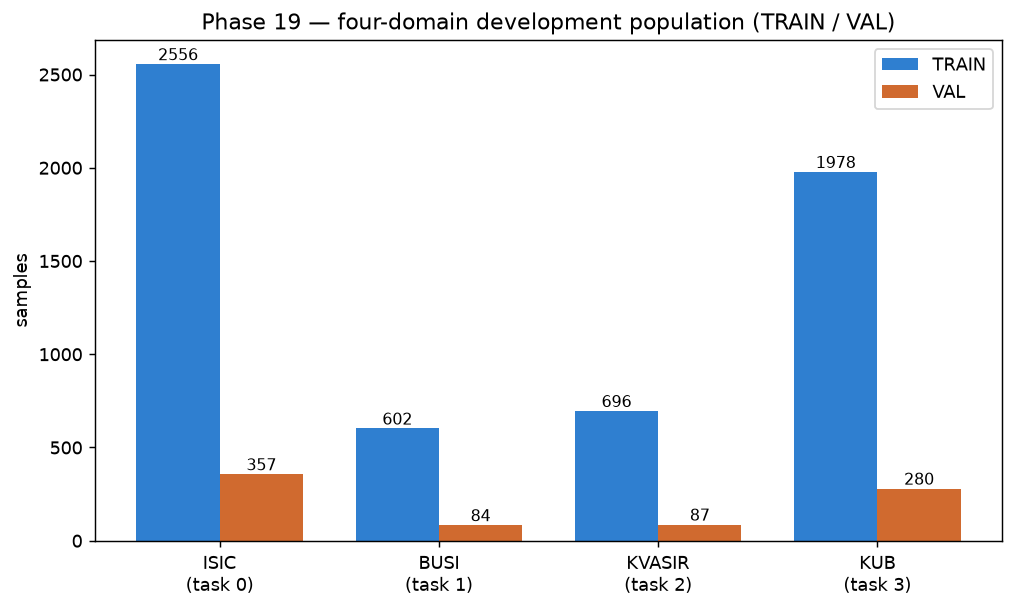

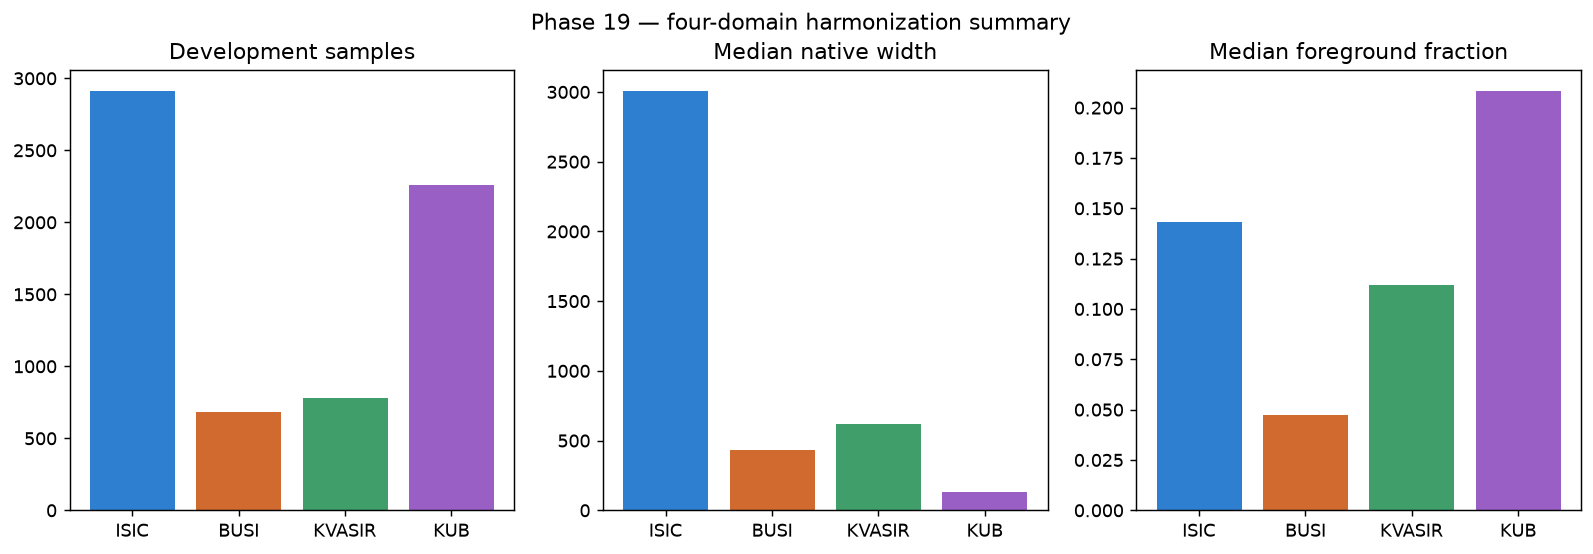

,dataset,development_share
0,ISIC,0.4387
1,BUSI,0.1033
2,KVASIR,0.1179
3,KUB,0.3401


In [15]:
display(Image(filename=str(FIG / "fig01_dataset_population.png")))
display(Image(filename=str(FIG / "fig08_domain_summary.png")))
share = (inv.set_index("dataset")["n_development"] / inv.n_development.sum()).round(4)
display(share.rename("development_share").reset_index())

## 16. Patient / group-key availability

In [16]:
grp = pd.read_csv(TAB / "phase19_group_key_availability.csv")
display(grp)

,dataset,n_development,patient_id_available_frac,case_id_available_frac,group_key_source,n_groups,grouping_used_for_split,leakage_risk_note
0,ISIC,2913,0.0,0.0,NONE_AVAILABLE,0,False,no patient metadata; split relies on sample-le...
1,BUSI,686,0.0,0.0,reports/tables/phase05_busi_patient_group_mapp...,927,True,patient-disjoint grouping applied
2,KVASIR,783,0.0,0.0,NONE_AVAILABLE,0,False,no patient metadata; split relies on sample-le...
3,KUB,2258,1.0,0.0,manifest.patient_id,429,True,patient-disjoint grouping applied


## 17. Duplicate / leakage safeguards

In [17]:
leak = jload(AUD / "phase19_leakage_safeguards.json")
display(pd.DataFrame([
    ("manifest version", leak["manifest_version"]),
    ("leakage status", leak["leakage_status"]),
    ("remediation reason", leak["remediation_reason"]),
    ("quarantined samples", leak["quarantined_samples"]),
    ("quarantined by dataset", json.dumps(leak["quarantined_by_dataset"])),
    ("duplicate risk groups", leak["duplicate_risk_groups"]),
    ("KUB TRAIN/VAL patient overlap", leak["kub_patient_overlap_train_val"]),
    ("KUB patient-disjoint", leak["kub_patient_disjoint"]),
    ("sample_id TRAIN/VAL overlap", leak["sample_id_overlap_train_val"]),
], columns=["safeguard", "value"]))
assert leak["kub_patient_disjoint"]
assert leak["sample_id_overlap_train_val"] == 0
print("residual risk:", leak["residual_risk"])

,safeguard,value
0,manifest version,phase4_v3
1,leakage status,REMEDIATED
2,remediation reason,Phase-05 leakage audit and remediation (Parts ...
3,quarantined samples,118
4,quarantined by dataset,"{""BUSI"": 67, ""ISIC"": 46, ""KUB"": 4, ""KVASIR"": 1}"
5,duplicate risk groups,76
6,KUB TRAIN/VAL patient overlap,0
7,KUB patient-disjoint,True
8,sample_id TRAIN/VAL overlap,0


residual risk: Cross-domain near-duplicate detection across the newly combined four-domain development pool is not yet established. No blocker found, but Phase 20 should re-assert the duplicate audit on the combined pool.


## 18. Metadata classification

In [18]:
meta = pd.read_csv(TAB / "phase19_metadata_governance.csv")
display(meta[["field", "classification", "phase19_disposition"]])
counts = meta["classification"].value_counts().to_dict()
print("classification counts:", counts)
assert set(counts) <= {"CONDITIONING_ALLOWED", "REPORTING_ONLY", "FORBIDDEN_AS_INPUT"}
assert (meta[meta["field"] == "category"]["classification"].iloc[0]) == "REPORTING_ONLY"
print("KUB category labels are REPORTING_ONLY: OK")

,field,classification,phase19_disposition
0,dataset,CONDITIONING_ALLOWED,May be used as a FiLM task-conditioning input ...
1,task_id,CONDITIONING_ALLOWED,Canonical FiLM conditioning key.
2,split,REPORTING_ONLY,Used only to scope loaders and reporting.
3,sample_id,REPORTING_ONLY,Never a model input.
4,patient_id,FORBIDDEN_AS_INPUT,Used ONLY for leakage-safe grouping where avai...
5,case_id,FORBIDDEN_AS_INPUT,Used ONLY for leakage-safe grouping where avai...
6,category,REPORTING_ONLY,May be reported for stratification. MUST NOT c...
7,image_path,REPORTING_ONLY,Path-derived regime may be used for stratified...
8,mask_path,FORBIDDEN_AS_INPUT,Evaluation only.
9,width / height,REPORTING_ONLY,Not a conditioning input under the frozen size...


classification counts: {'REPORTING_ONLY': 5, 'FORBIDDEN_AS_INPUT': 4, 'CONDITIONING_ALLOWED': 2}
KUB category labels are REPORTING_ONLY: OK


## 19. Harmonized sample schema

In [19]:
schema = pd.read_csv(TAB / "phase19_harmonized_schema.csv")
display(schema)

,field,kind,shape,dtype,range,semantics,governance_class
0,image,tensor,"(C, H, W)",float32,"[0,1]","C in {1,3} per channel policy; H=W=canonical size",CONDITIONING_INPUT
1,mask,tensor,"(1, H, W)",float32,"{0,1}",canonical foreground = (mask > 0),TARGET
2,dataset,str,scalar,-,-,canonical dataset name,CONDITIONING_ALLOWED
3,task_id,int64,scalar,-,-,authoritative task registry,CONDITIONING_ALLOWED
4,sample_id,str,scalar,-,-,stable hash,REPORTING_ONLY
5,split,str,scalar,-,-,TRAIN/VAL only,REPORTING_ONLY
6,image_native_size,"tuple[int,int]","(W,H)",-,-,"pre-resize native size, audit only",REPORTING_ONLY
7,resize_scale,float,scalar,-,-,"aspect-preserving scale = min(size/w, size/h)",REPORTING_ONLY


## 20. Harmonized batch schema

In [20]:
from src.data.multidomain_dataset import MultiDomainDataset, harmonized_collate

_ds = MultiDomainDataset(ROOT / "manifests/phase4_v3/val.csv", split="VAL", size=512, datasets=["ISIC"])
_batch = harmonized_collate([_ds[i] for i in range(3)])
display(pd.DataFrame([
    ("image", str(tuple(_batch["image"].shape)), str(_batch["image"].dtype),
     f"[{float(_batch['image'].min()):.3f}, {float(_batch['image'].max()):.3f}]"),
    ("mask", str(tuple(_batch["mask"].shape)), str(_batch["mask"].dtype),
     f"values {sorted(set(np.unique(_batch['mask'].numpy()).tolist()))}"),
    ("task_id", str(tuple(_batch["task_id"].shape)), str(_batch["task_id"].dtype),
     str(_batch["task_id"].tolist())),
    ("dataset", "list[str]", "-", str(_batch["dataset"])),
    ("sample_id", "list[str]", "-", str(_batch["sample_id"])),
    ("split", "list[str]", "-", str(_batch["split"])),
], columns=["field", "shape", "dtype", "example"]))

,field,shape,dtype,example
0,image,"(3, 3, 512, 512)",torch.float32,"[0.000, 1.000]"
1,mask,"(3, 1, 512, 512)",torch.float32,"values [0.0, 1.0]"
2,task_id,"(3,)",torch.int64,"[0, 0, 0]"
3,dataset,list[str],-,"['ISIC', 'ISIC', 'ISIC']"
4,sample_id,list[str],-,"['0012a4db87568a44b326db45138d2147', '011cdf85..."
5,split,list[str],-,"['VAL', 'VAL', 'VAL']"


## 21. Preprocessing contract

In [21]:
pre = jload(AUD / "phase19_preprocessing_contract.json")
display(Markdown("### Image"))
display(pd.DataFrame(sorted(pre["image"].items()), columns=["key", "value"]))
display(Markdown("### Mask"))
display(pd.DataFrame(sorted(pre["mask"].items()), columns=["key", "value"]))
display(Markdown("### Spatial"))
display(pd.DataFrame(sorted(pre["spatial"].items()), columns=["key", "value"]))

### Image

,key,value
0,channel_decision_owner,Phase 24 (architecture specification); Phase 1...
1,channel_policy_alternatives,"[GRAYSCALE_1CH, RGB_3CH]"
2,channel_policy_default,RGB_3CH
3,color_handling,{'RGB_3CH': 'PIL convert('RGB'); native-L doma...
4,intensity_normalization,"divide by 255.0 -> [0,1]"
5,intensity_range_native,"[0,255]"
6,model_dtype,float32
7,observed_native_modes_per_domain,"{'ISIC': ['RGB'], 'BUSI': ['L'], 'KVASIR': ['R..."
8,storage_dtype,uint8


### Mask

,key,value
0,background_rule,mask == 0
1,binarization_threshold,strictly greater than zero; no value threshold...
2,channel_reduction,3-D masks reduced to first channel
3,foreground_rule,mask > 0 (src.utils.targets.binarize_mask)
4,interpolation,NEAREST
5,model_dtype,float32
6,never_test_mask_eq_1,True
7,storage_dtype,uint8


### Spatial

,key,value
0,default_size,512
1,image_resample,BILINEAR
2,implementation,src.data.transforms.SegmentationTransform
3,mask_resample,NEAREST
4,pad_fill,0
5,policy,aspect-preserving resize + centre pad
6,scale_formula,"scale = min(size / w, size / h)"
7,supported_sizes,"[256, 512, 768, 1024]"


## 22. Mask contract

In [22]:
display(pd.DataFrame(sorted(pre["mask"].items()), columns=["key", "value"]))
print("canonical foreground rule:", pre["mask"]["foreground_rule"])
print("never test mask == 1     :", pre["mask"]["never_test_mask_eq_1"])

,key,value
0,background_rule,mask == 0
1,binarization_threshold,strictly greater than zero; no value threshold...
2,channel_reduction,3-D masks reduced to first channel
3,foreground_rule,mask > 0 (src.utils.targets.binarize_mask)
4,interpolation,NEAREST
5,model_dtype,float32
6,never_test_mask_eq_1,True
7,storage_dtype,uint8


canonical foreground rule: mask > 0  (src.utils.targets.binarize_mask)
never test mask == 1     : True


## 23. Augmentation boundary

In [23]:
display(pd.DataFrame(sorted(pre["augmentation_boundary"].items()), columns=["key", "value"]))
print("train-only paired augmentation; VAL augmentation disabled.")

,key,value
0,implementation,src.data.transforms.SegmentationTransform(trai...
1,mask_resample_during_augmentation,NEAREST
2,operations,"[horizontal mirror (p=0.5), rotation +/-5 deg,..."
3,paired,True
4,train_only,True
5,val_augmentation,disabled


train-only paired augmentation; VAL augmentation disabled.


## 24. Evaluation metric contract

In [24]:
ev = jload(AUD / "phase19_evaluation_contract.json")
display(pd.DataFrame(sorted(ev["metric_domain"].items()), columns=["key", "value"]))
display(pd.DataFrame(sorted(ev["metrics"].items()), columns=["key", "value"]))
display(pd.DataFrame(sorted(ev["aggregation"].items()), columns=["key", "value"]))
print("TEST evaluation:", ev["test_evaluation"])

,key,value
0,frozen_domain,DETECTION (component overlap >= 1 pixel)
1,note,Phase 19 freezes the domain only; no metric is...


,key,value
0,boundary,[hd95]
1,epsilon,0.0
2,implementation,src.metrics.segmentation.binary_metrics
3,pixel,"[dice, iou, precision, recall, f1]"
4,threshold,0.5


,key,value
0,macro_domain,unweighted mean of the four per-domain macro v...
1,micro,reported separately; never used for selection
2,per_dataset,macro (unweighted mean of per-image metrics) w...


TEST evaluation: FORBIDDEN_IN_PHASE_19


## 25. Prospective Stage-B invariants

In [25]:
smoke = jload(AUD / "phase19_loader_smoke_test.json")
invariants = {
    "four_domains_present": set(inv["dataset"]) == {"ISIC", "BUSI", "KVASIR", "KUB"},
    "task_ids_frozen": bool(reg["manifest_agrees"].all()),
    "foreground_rule_uniform": bool(inv["fg_native_rule"].eq("mask > 0").all()),
    "test_reads_zero": True,
    "loaders_smoke_pass": bool(smoke["all_checks_passed"]),
    "test_rejected_by_dataset": bool(smoke["test_rejected_by_dataset"]),
    "test_rejected_by_loader": bool(smoke["test_rejected_by_loader"]),
    "no_training": not smoke["training_performed"],
    "no_optimizer": not smoke["optimizer_created"],
    "no_backward": not smoke["backward_performed"],
    "no_checkpoint": not smoke["checkpoint_created"],
    "stage_b_active": bool(auth["stage_b_activation"]["active"]),
    "phase20_not_started": auth["locks"]["future_phase_locks"]["phase_20"] == "NOT_STARTED_AND_NOT_AUTHORIZED",
}
display(pd.DataFrame(sorted(invariants.items()), columns=["invariant", "holds"]))
assert all(invariants.values()), [k for k, v in invariants.items() if not v]
print("All Stage-B invariants hold.")

,invariant,holds
0,foreground_rule_uniform,True
1,four_domains_present,True
2,loaders_smoke_pass,True
3,no_backward,True
4,no_checkpoint,True
5,no_optimizer,True
6,no_training,True
7,phase20_not_started,True
8,stage_b_active,True
9,task_ids_frozen,True


All Stage-B invariants hold.


## 26. Legacy-code reuse map

In [26]:
rd = pd.DataFrame(reuse["entries"])
display(rd[["component_id", "old_role", "reuse_type", "reason"]])
display(rd["reuse_type"].value_counts().rename("count").reset_index())

,component_id,old_role,reuse_type,reason
0,legacy.omni_seg.global_config,"Multi-domain dataset naming, modality + target...",REFERENCE_ONLY,The legacy config targets a different domain s...
1,legacy.medfilm_seg.global_config,"3-domain task-ID registry (isic2018=0, busi=1,...",REFERENCE_ONLY,Task IDs agree with manifests/phase4_v3; hyper...
2,legacy.medfilm_seg_v2.preprocessing,Orientation-aware image opening and radiograph...,ADAPT,The current canonical transform already resize...
3,legacy.medfilm_seg_v2.near_duplicates,Content-hash based near-duplicate / entity gro...,ADAPT,The jup repo already remediated leakage in pha...
4,legacy.medfilm_seg_v2.weak_segmentation_dataset,Sparse CAM-seed weak-label dataset with 0/1..2...,DO_NOT_REUSE,The RA-MedFiLM-Seg++ program is fully supervis...
5,legacy.medfilm_seg_v2.film_module,FeatureWiseLinearModulation: F_hat = (1 + gamm...,REFERENCE_ONLY,"Zero-init identity-at-start is a valuable, ver..."
6,legacy.medfilm_seg_v2.locked_test_contract,Explicit locked-TEST contract with prohibited ...,REFERENCE_ONLY,"The jup repo already has a stronger, independe..."
7,legacy.safeseg.notebooks,"Multi-dataset (isic2018, kits23, mms, montgome...",REFERENCE_ONLY,Different domain set; no reusable code path. H...
8,legacy.final.external_test_ds,External evaluation dataset engineering for th...,REFERENCE_ONLY,Phase 32 owns external validation; Phase 19 mu...
9,jup.src.data.transforms,Canonical aspect-preserving resize + centre pa...,DIRECT_REUSE,Already validated on clean-v3 KUB; satisfies t...


,reuse_type,count
0,REFERENCE_ONLY,6
1,DIRECT_REUSE,3
2,ADAPT,2
3,DO_NOT_REUSE,1


## 27. Unresolved harmonization issues

In [27]:
protocol = jload(AUD / "phase19_multidomain_harmonization_protocol.json")
for i, issue in enumerate(protocol["unresolved_issues"], 1):
    print(f"{i}. {issue}")

1. Model-input channel policy (1-ch grayscale vs 3-ch RGB) is frozen as TWO deterministic converters; the single final selection is deferred to Phase 24 (architecture).
2. KUB native masks carry heterogeneous nonzero label vocabularies; the canonical >0 rule handles them, but per-category label semantics remain REPORTING_ONLY.
3. Cross-domain near-duplicate detection beyond the phase4_v3 remediation is not yet established for the newly combined four-domain pool.
4. BUSI/KUB acquisition-regime stratification is available via path only; it is not a model input.


## 28. Artifact provenance

In [28]:
rows = []
for name, digest in sorted(protocol["artifacts"].items()):
    base = TAB if name.endswith(".csv") else AUD
    path = base / name
    rows.append({
        "artifact": name,
        "path": str(path.relative_to(ROOT)).replace("\\", "/"),
        "recorded_sha256": digest,
        "on_disk_sha256": sha256_file(path),
        "matches": digest == sha256_file(path),
    })
prov = pd.DataFrame(rows)
display(prov[["artifact", "recorded_sha256", "matches"]])
assert prov["matches"].all()

figrows = [{
    "figure": k,
    "path": f"reports/figures/phase19_harmonization/{k}.png",
    "recorded_sha256": v,
    "matches": v == sha256_file(FIG / f"{k}.png"),
} for k, v in sorted(protocol["figures"].items())]
figprov = pd.DataFrame(figrows)
display(figprov[["figure", "matches"]])
assert figprov["matches"].all()
print("All Phase-19 artifacts and figures SHA-verified.")

,artifact,recorded_sha256,matches
0,phase19_dataset_inventory.csv,56188f9a7647d77d761eb5f6eac20ec5700024be968459...,True
1,phase19_evaluation_contract.json,7f7f18fc17e1f377ef8fefcd9f4c9280cd46443b1b1f50...,True
2,phase19_group_key_availability.csv,87b9c5d5c68332c8e9012c8639ef708acae2d2b76a1cd1...,True
3,phase19_harmonized_schema.csv,c64d4c434c4692214da87aaf7bb4803c49dc2f47e84c0c...,True
4,phase19_image_measurements.csv,4879967cb6e3c67eddf51098f92cc9ae5481b58dd40c20...,True
5,phase19_leakage_safeguards.json,b41307eb5c36401e7882f217e953163fb02d8c1a47fe48...,True
6,phase19_legacy_evidence_reuse_map.json,415eeedea6f9f7f1590dcf3e9dbaf4eea3783624793bf0...,True
7,phase19_loader_smoke_test.json,225bcde30e4ac259d4a072c88b6ef75f9633e0d41e31ca...,True
8,phase19_mask_measurements.csv,fc095e73d5f0b01bd8823978a6f4a880dffd3f358fe8a9...,True
9,phase19_metadata_governance.csv,269445e1d0ded5cdc55fa67162ffd76e64e29f4193e1e4...,True


,figure,matches
0,fig01_dataset_population,True
1,fig02_resolution_distributions,True
2,fig03_aspect_ratio_distributions,True
3,fig04_foreground_fraction,True
4,fig05_modality_composition,True
5,fig06_size_scatter,True
6,fig07_representative_pairs,True
7,fig08_domain_summary,True


All Phase-19 artifacts and figures SHA-verified.


## 29. Phase-20 entry criteria

In [29]:
crit = pd.read_csv(TAB / "phase19_phase20_entry_criteria.csv")
display(crit)
print("criteria met:", int(crit["met"].sum()), "/", len(crit))
assert crit["met"].all()

,criterion_id,criterion,requirement,current_status,met
0,E1,All four domains mapped,"ISIC, BUSI, KVASIR, KUB each present with TRAI...",4 domains mapped,True
1,E2,No unresolved label-semantic conflict,Single canonical foreground rule across domains,foreground = (mask > 0) for all four domains,True
2,E3,Task IDs frozen,task_id registry frozen and manifest-agreeing,registry frozen; manifest agrees = True,True
3,E4,Preprocessing frozen,phase19_preprocessing_contract_v1 FROZEN_FOR_P...,frozen,True
4,E5,Mask semantics frozen,"binary foreground, NEAREST interpolation, no v...",frozen,True
5,E6,Metadata policy frozen,every field classified exactly once,frozen,True
6,E7,TRAIN/VAL loaders smoke-tested,per-domain dataset + loader materialise batches,all_checks_passed = True,True
7,E8,No TEST reads,"TEST image/mask reads, inference and visualiza...",0,True
8,E9,Harmonized batch schema validated,"image (B,C,S,S), mask (B,1,S,S), task_id present",validated in smoke test,True
9,E10,No duplicate/leakage blocker,phase4_v3 remediation holds; no new blocker found,no blocker; cross-domain near-duplicate check ...,True


criteria met: 12 / 12


## 30. Current terminal state

In [30]:
state = {
    "H3": "CLOSED__FORMALLY_INSUFFICIENT",
    "regional_localizer_redesign": "DEFERRED",
    "phases_15_18": "DEFERRED_CONDITIONAL__NOT_EXECUTED",
    "stage_b": "ACTIVE",
    "phase_19": "AUTHORIZED / PROTOCOL + HARMONIZATION PREPARATION COMPLETE",
    "phase_20": "NOT_STARTED_AND_NOT_AUTHORIZED",
    "test": "CLOSED",
}
display(pd.DataFrame(sorted(state.items()), columns=["governance item", "state"]))

display(Markdown("### Final assertions"))
assert h3["scientific_label"] == "H3_SUPPLY_REDESIGN_INSUFFICIENT"
assert auth["status"] == "STAGE_B_AUTHORIZED__PHASE19_READY_TO_START"
assert protocol["status"] == "PROTOCOL_FROZEN__PHASE19_HARMONIZATION_PREPARATION_COMPLETE"
assert protocol["governance"]["training_performed"] is False
assert protocol["governance"]["inference_performed"] is False
assert protocol["governance"]["phase_20_started"] is False
print("✓ All Phase-19 harmonization assertions passed.")
print("TERMINAL STATE: POST_H3_REGIONAL_BRANCH_DEFERRED__STAGE_B_ACTIVE__PHASE19_READY")

,governance item,state
0,H3,CLOSED__FORMALLY_INSUFFICIENT
1,phase_19,AUTHORIZED / PROTOCOL + HARMONIZATION PREPARAT...
2,phase_20,NOT_STARTED_AND_NOT_AUTHORIZED
3,phases_15_18,DEFERRED_CONDITIONAL__NOT_EXECUTED
4,regional_localizer_redesign,DEFERRED
5,stage_b,ACTIVE
6,test,CLOSED


### Final assertions

✓ All Phase-19 harmonization assertions passed.
TERMINAL STATE: POST_H3_REGIONAL_BRANCH_DEFERRED__STAGE_B_ACTIVE__PHASE19_READY
